|<h2>Course:</h2>|<h1><a href="https://derivingsystems.com/course.html" target="_blank">Build your own vLLM: inference engines from the memory system up</a></h1>|
|-|:-:|
|<h2>Part 1:</h2>|<h1>The Naive Loop<h1>|
|<h2>Section:</h2>|<h1>The KV cache<h1>|
|<h2>Lecture:</h2>|<h1><b>The cache in bytes: predict it, measure it, find the trap<b></h1>|

<br>

<h5><b>Course repo:</b> <a href="https://github.com/Venugopalan2610/vllm-from-scratch" target="_blank">github.com/Venugopalan2610/vllm-from-scratch</a></h5>
<h5><b>The derivations:</b> <a href="https://derivingsystems.com" target="_blank">derivingsystems.com</a></h5>
<i>The notebooks build the intuition. The ladder in app/ makes you build the thing.</i>

In [1]:
# find the repo root. The directory you start from does not matter.
import sys
from pathlib import Path
ROOT = next(folder for folder in [Path.cwd(), *Path.cwd().parents]
            if (folder/'cudalib').is_dir())
sys.path.insert(0, str(ROOT))

import numpy as np
import torch
import matplotlib.pyplot as plt
from transformers import AutoConfig, AutoModelForCausalLM

import matplotlib_inline.backend_inline
matplotlib_inline.backend_inline.set_matplotlib_formats('svg')

import cudalib

/home/venugopalan/vllm-from-scratch/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# What it costs to remember

The cache changes $O(N^2)$ compute into $O(N)$ compute. To do that it keeps
every K and V that it ever computed. That is a bill in bytes, and the next
twenty stages are about that bill.

In [2]:
model = AutoModelForCausalLM.from_pretrained(
          'Qwen/Qwen3-1.7B', dtype=torch.bfloat16).cuda().eval()
config = model.config

Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 311/311 [00:00<00:00, 13743.41it/s]

### Predict the cost from the config first

In [3]:
print(f'layers           {config.num_hidden_layers}')
print(f'attention heads  {config.num_attention_heads}')
print(f'kv heads         {config.num_key_value_heads}')
print(f'hidden size      {config.hidden_size}')

layers           28
attention heads  16
kv heads         8
hidden size      2048


In [4]:
# 2 for K and V, one entry per layer, per kv head, per element of head_dim
head_dim  = config.hidden_size // config.num_attention_heads
predicted = 2 * config.num_hidden_layers * config.num_key_value_heads * head_dim * 2

print(f'head_dim = {config.hidden_size} / {config.num_attention_heads} = {head_dim}')
print(f'predicted: {predicted/1024:.0f} KB per token')

head_dim = 2048 / 16 = 128
predicted: 112 KB per token


### Now measure it

In [5]:
@torch.inference_mode()
def cache_bytes(num_tokens):
  token_ids = torch.randint(0, 1000, (1,num_tokens), device='cuda')
  cache = model(token_ids, use_cache=True).past_key_values
  return sum(tensor.numel()*tensor.element_size()
             for layer in cache.layers for tensor in (layer.keys, layer.values))

measured = cache_bytes(256) / 256
print(f'measured:  {measured/1024:.0f} KB per token')
print(f'predicted: {predicted/1024:.0f} KB per token')
print(f'\nmeasured / predicted = {measured/predicted:.2f}')

measured:  112 KB per token
predicted: 112 KB per token

measured / predicted = 1.00


### The prediction agrees. Do not trust it yet.

You derived `head_dim` from two other fields, and the answer came out right.
That proves less than it seems. Look at a real cache entry, and check the
shape that you assumed.

In [6]:
@torch.inference_mode()
def one_layer(num_tokens=256):
  token_ids = torch.randint(0, 1000, (1,num_tokens), device='cuda')
  return model(token_ids, use_cache=True).past_key_values.layers[0].keys

keys = one_layer()
print('keys shape (batch, kv_heads, tokens, head_dim):', tuple(keys.shape))
print(f'\nreal head_dim:    {keys.shape[-1]}')
print(f'assumed head_dim: {head_dim}')
print(f'\ncfg.head_dim = {getattr(config, "head_dim", None)}')

keys shape (batch, kv_heads, tokens, head_dim): (1, 8, 256, 128)

real head_dim:    128
assumed head_dim: 128

cfg.head_dim = 128


### The same formula on two other Qwen3 models

The formula agreed on this model. Now try it on Qwen3-0.6B and Qwen3-4B. You
need only their `config.json` files, a few KB each. The cell loads no
weights.

In [7]:
print(f"{'model':<11} {'hidden':>6} {'heads':>5} {'derived':>8} {'real':>5} "
      f"{'heads x head_dim':>17} {'KB/token':>9} {'error':>6}")
for name in ('Qwen/Qwen3-0.6B', 'Qwen/Qwen3-1.7B', 'Qwen/Qwen3-4B'):
  other = AutoConfig.from_pretrained(name)
  derived = other.hidden_size // other.num_attention_heads
  kv_per_token = lambda dim: 2 * other.num_hidden_layers * other.num_key_value_heads * dim * 2
  print(f'{name[5:]:<11} {other.hidden_size:>6} {other.num_attention_heads:>5} '
        f'{derived:>8} {other.head_dim:>5} '
        f'{other.num_attention_heads * other.head_dim:>17} '
        f'{kv_per_token(other.head_dim)/1024:>9.0f} '
        f'{kv_per_token(other.head_dim)/kv_per_token(derived):>5.1f}x')

model       hidden heads  derived  real  heads x head_dim  KB/token  error


Qwen3-0.6B    1024    16       64   128              2048       112   2.0x


Qwen3-1.7B    2048    16      128   128              2048       112   1.0x


Qwen3-4B      2560    32       80   128              4096       144   1.6x


### The formula worked here by luck

All three models use `head_dim` 128. Only the number of heads changes. For
Qwen3-1.7B, 2048 / 16 is 128 by coincidence. For Qwen3-0.6B the derived
value is too small by 2x, and for Qwen3-4B by 1.6x.

Look at the column `heads x head_dim`. It is the width of the attention space,
and it does not have to equal `hidden_size`. The math of attention does not
need it:

```
q   = x @ W_q       W_q: hidden_size -> num_heads    * head_dim
k   = x @ W_k       W_k: hidden_size -> num_kv_heads * head_dim
v   = x @ W_v       W_v: hidden_size -> num_kv_heads * head_dim
out = attn @ W_o    W_o: num_heads * head_dim -> hidden_size
```

`W_q` projects into a new space, and `W_o` projects back. The rule
`head_dim = hidden_size / num_heads` comes from the original Transformer
paper. It is a convention, not a requirement. Designers choose `head_dim`
separately. Attention kernels are fastest at 64, 128 and 256, so Qwen3 keeps
128 and changes the number of heads.

Read `head_dim` from the config. Do not derive it. If you derive it, a
capacity plan for Qwen3-0.6B is wrong by 2x. Production finds that error. A
review does not.

In [8]:
head_dim  = config.head_dim
predicted = 2 * config.num_hidden_layers * config.num_key_value_heads * head_dim * 2
print(f'predicted: {predicted/1024:.0f} KB per token')
print(f'measured:  {measured/1024:.0f} KB per token')

predicted: 112 KB per token
measured:  112 KB per token


### What the cache stores: the output, not the weight

`hidden_size` is not in the formula for the cache. The reason: the cache
stores the vector that `W_k` makes, not `W_k`. One token, one layer:

```
     x_t                        W_k                            k_t
  (the token)            (the weight, stored 1 time)    (the output, stored
                                                          in the KV cache)

                       <------- 1024 columns ------->
                       +------+------+-----+------+
   +---+               |head 0|head 1| ... |head 7|
   |   |               | 128  | 128  |     | 128  |
   |   |               |      |      |     |      |       +------+
   | 2 |               |      |      |     |      |       |h0 128|
   | 0 |      @        |      |      |     |      |   =   |h1 128|
   | 4 |               |      |      |     |      |       | ...  |
   | 8 |               |      |      |     |      |       |h7 128|
   |   |               |      |      |     |      |       +------+
   |   |               |      |      |     |      |        1024
   +---+               +------+------+-----+------+       numbers
   2048                 2048 rows  (hidden_size)
  numbers
                        2048 x 1024 = 2,097,152 numbers
                        = 4 MB
```

Each number of `k_t` is the dot product of all 2048 numbers of `x_t` with one
column of `W_k`. The `hidden_size` axis disappears in the product. So the
cache entry has `num_kv_heads x head_dim` numbers, and the size of the
weight does not matter.

Each new token adds one row. All rows use the same `W_k`:

```
  K cache for layer 0             <---- 8 heads x 128 = 1024 ---->

  token 0    k_0 = x_0 @ W_k    [ h0 | h1 | h2 | h3 | h4 | h5 | h6 | h7 ]  2 KB
  token 1    k_1 = x_1 @ W_k    [ h0 | h1 | h2 | h3 | h4 | h5 | h6 | h7 ]  2 KB
  token 2    k_2 = x_2 @ W_k    [ h0 | h1 | h2 | h3 | h4 | h5 | h6 | h7 ]  2 KB
    ...          ...                           ...                        ...
  token N-1  k_N-1              [ h0 | h1 | h2 | h3 | h4 | h5 | h6 | h7 ]  2 KB
                                                                        --------
                                                                        N x 2 KB
```

Check both pictures against the real tensors.

In [9]:
weight = model.model.layers[0].self_attn.k_proj.weight     # torch stores (out, in)
print(f'W_k of layer 0:       {tuple(weight.shape[::-1])} = {weight.numel():>9,} numbers '
      f'= {weight.numel()*weight.element_size()/2**20:.0f} MB, stored 1 time')
row = keys[0, :, 0, :]                                     # (kv_heads, head_dim) of token 0
print(f'k of 1 token, 1 layer: {tuple(row.shape)}      = {row.numel():>9,} numbers '
      f'= {row.numel()*row.element_size()/1024:.0f} KB, stored for each token')
print(f'\nK and V, all {config.num_hidden_layers} layers: '
      f'2 x {config.num_hidden_layers} x {row.numel()*row.element_size()/1024:.0f} KB '
      f'= {2*config.num_hidden_layers*row.numel()*row.element_size()/1024:.0f} KB for each token')

W_k of layer 0:       (2048, 1024) = 2,097,152 numbers = 4 MB, stored 1 time
k of 1 token, 1 layer: (8, 128)      =     1,024 numbers = 2 KB, stored for each token

K and V, all 28 layers: 2 x 28 x 2 KB = 112 KB for each token


The picture shows the cache of one layer, with the shapes of Qwen3-1.7B. The
blue rows are the K and V of earlier tokens. The orange rows are what one new
token adds. Multiply by the 28 layers, and you get the number that
`kv_bytes_per_token` returns in stage 02.

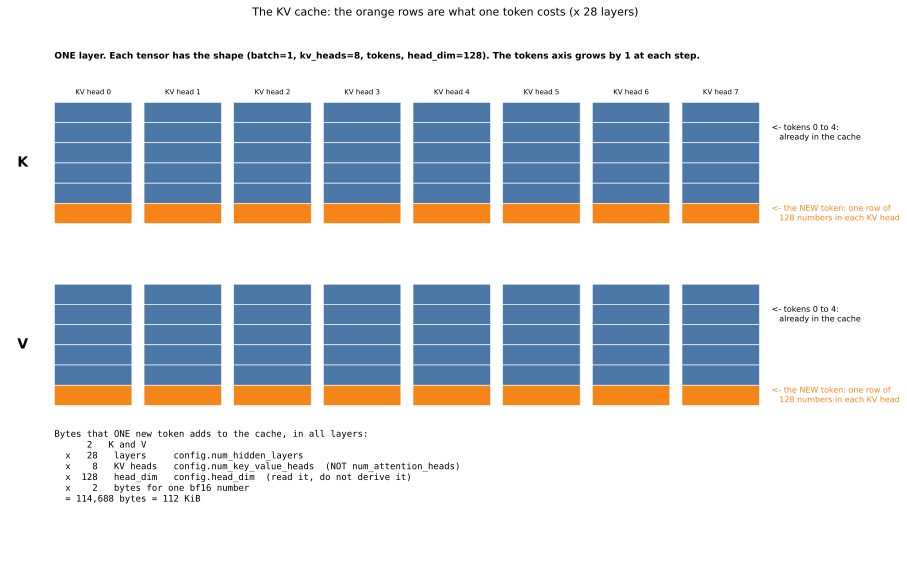

In [10]:
# The picture. course/pictures.py draws it. It needs no GPU.
from course import pictures
pictures.cache_tensor()

# The bill

In [11]:
free_bytes = torch.cuda.mem_get_info()[0]
print(f'{free_bytes/1e9:.1f} GB free on this card right now\n')

for context_len in (512, 2048, 8192, 32768):
  bytes_per_sequence = context_len * predicted
  print(f'{context_len:>6} tokens: {bytes_per_sequence/1e6:8.1f} MB per sequence, '
        f'{free_bytes/bytes_per_sequence:6.0f} sequences fit')

8.6 GB free on this card right now

   512 tokens:     58.7 MB per sequence,    146 sequences fit
  2048 tokens:    234.9 MB per sequence,     36 sequences fit
  8192 tokens:    939.5 MB per sequence,      9 sequences fit
 32768 tokens:   3758.1 MB per sequence,      2 sequences fit


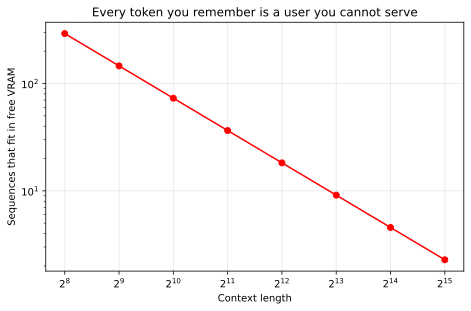

In [12]:
context_lens = np.array([256,512,1024,2048,4096,8192,16384,32768])
sequences_that_fit = free_bytes / (context_lens * predicted)

plt.figure(figsize=(7.5,4.5))
plt.plot(context_lens, sequences_that_fit, 'ro-')
plt.xscale('log', base=2)
plt.yscale('log')
plt.xlabel('Context length')
plt.ylabel('Sequences that fit in free VRAM')
plt.title('Every token you remember is a user you cannot serve')
plt.grid(alpha=.3)
plt.show()

### The weights stay fixed. The cache grows.

```
  memory
    ^
    |                                              /  KV cache
    |                                           /     (grows with N)
    |                                        /
    |                                     /
    |                                  /
    |---------------------------/---------------------  weights
    |                        /                          (fixed)
    |                     /
    |                  /
    |               /
    |            /
    |         /
    |      /
    |   /
    +------------------------------------------------->  tokens (N)
                          ^
                          the cache is as big as the weights
```

Find the crossover for this model.

In [13]:
weight_bytes = sum(weight.numel()*weight.element_size() for weight in model.parameters())
print(f'weights:   {weight_bytes/1e9:.2f} GB, fixed')
print(f'KV cache:  {predicted/1024:.0f} KB for each token')
print(f'crossover: {weight_bytes/predicted:,.0f} tokens')

weights:   3.44 GB, fixed
KV cache:  112 KB for each token
crossover: 30,004 tokens


### This plot is the optimistic version

The plot assumes that you allocate exactly what you use. No engine did that
before vLLM.

An engine reserved `max_len` for a sequence the moment it arrived. Your guess
and the real length differ, and the engine wastes the difference.

The vLLM paper measured that waste at **60 to 80 percent** of KV memory.
Divide the red line by four.

Stage 06 makes you build the allocator that recovers the memory. Stage 07
makes attention read through it.

    ./vc guide 6

# One cache for each request

A cache holds the K and V of every token that went into it. That is the
point of a cache. It is also a trap.

**Given:** request A, `'The capital of France is'`, and the cache that it
filled. Request B, `'The language that people speak there is'`, from a
different user.

**Asked:** request B uses the cache of A by mistake. This happens when a
cache lives in a global variable, or in a default argument. What does B
see? Does its next token change?

Write your prediction first.

In [14]:
my_prediction = None      # the same next token as a new cache? yes or no

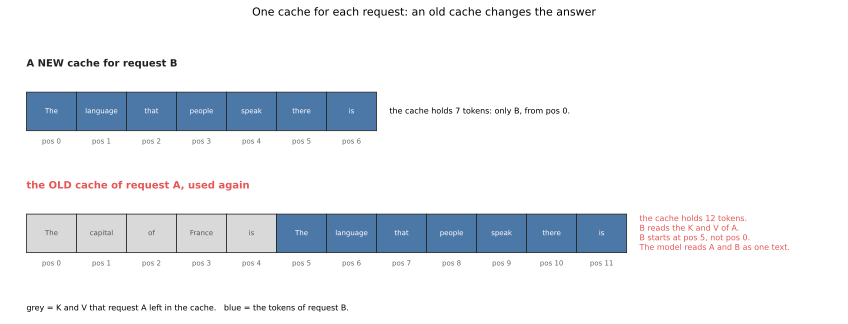

In [15]:
# The picture. course/pictures.py draws it. It needs no GPU.
from course import pictures
pictures.stale_cache()

In [16]:
from transformers import AutoTokenizer
tokenizer = AutoTokenizer.from_pretrained('Qwen/Qwen3-1.7B')

ids_a = tokenizer('The capital of France is', return_tensors='pt').input_ids.cuda()
ids_b = tokenizer('The language that people speak there is', return_tensors='pt').input_ids.cuda()

with torch.inference_mode():
  cache_of_a = model(ids_a, use_cache=True).past_key_values        # request A
  fresh = model(ids_b, use_cache=True)                             # request B, a NEW cache
  stale = model(ids_b, past_key_values=cache_of_a, use_cache=True) # request B, the cache of A

def next_token(model_output):
  return repr(tokenizer.decode(int(model_output.logits[0, -1].argmax())))

print(f'request B, a new cache:     {fresh.past_key_values.get_seq_length():>2} tokens in the cache, '
      f'next token {next_token(fresh)}')
print(f'request B, the cache of A:  {stale.past_key_values.get_seq_length():>2} tokens in the cache, '
      f'next token {next_token(stale)}')
print(f'\nyou predicted: {my_prediction}')

request B, a new cache:      7 tokens in the cache, next token ' English'
request B, the cache of A:  12 tokens in the cache, next token ' French'

you predicted: None


The old cache does not crash. It returns a fluent, plausible answer, and the
answer is wrong for user B. "There" now means France, because B reads the K
and V of A.

Prove that claim with a number. If B reads A, then the logits of B with the
old cache must equal the logits of the text A + B, read as one text.

In [17]:
with torch.inference_mode():
  joined = model(torch.cat([ids_a, ids_b], dim=1), use_cache=False).logits[0, -1].float()
stale_logits = stale.logits[0, -1].float()
fresh_logits = fresh.logits[0, -1].float()
print(f'largest difference, the old cache against A + B as one text: {(stale_logits - joined).abs().max():6.3f}')
print(f'largest difference, the old cache against B alone:            {(stale_logits - fresh_logits).abs().max():6.3f}')

largest difference, the old cache against A + B as one text:  0.250
largest difference, the old cache against B alone:            10.312


The first difference is small. It is the rounding of bf16: a cached pass and a
full pass add the numbers in a different order (the challenge of this
section, Exercise 5). The second difference is many times larger. The old
cache made B into the end of A.

**Rule.** Make a new cache for each request. Stage 02 has a check that runs
two requests in a row, and it fails on exactly this bug. In stage 06 the
same rule comes back: a freed block holds old K and V, and nothing may read
it before a new token writes it.

### Where this goes in the ladder

The stages in `app/` that use this section. Read the right column before you
start the stage: the section does not teach it.

| Stage | It uses from this section | New in the stage |
|---|---|---|
| 02 `cached_generate` | The challenge of this section: both loops, and the proof that they agree. This notebook: one cache for each request. | Stop at the stop tokens. Return only the new ids. A check runs two requests in a row. |
| 02 `kv_bytes_per_token` | This notebook: read `head_dim` from the config. The picture of the cache. | Nothing. The function is the formula. |
| 03 `time_decode` | Notebook 1, `decode_ms`: give each pass the cache of the pass before it. | Time `steps` passes and divide. Compare the GB/s with the peak. |
| 06 the block allocator | This notebook, "The bill": 60 to 80 percent of KV memory goes to reservation. | Blocks, [block tables](../../GLOSSARY.md#block-table) and a free list, in plain Python. |